# Textklassifikation mit RNN: GermEval 2018

*GermEval* – für German Evaluation – ist ein jährlicher Wettbewerb im Bereich Natural Language Processing für deutschsprachige Texte (s. [https://germeval.github.io/](https://germeval.github.io/)).

Im Jahr 2018 ging es um die Erkennung von Beleidigungen in deutschsprachigen Tweets.

In dieser Aufgabe wollen wir Rekurrente Neuronale Netze (RNN) zur Klassifikation nutzen. Zunächst einmal starten wir mit Vorarbeiten.

## Format der Daten

Die Trainings- und Testdaten liegen als mit Tabulatoren separierte Textdateien (Tab Separated Values – TSV) vor. Uns interessieren die erste Spalte (der Tweet) und die zweite Spalte (`OFFENSE` für Beleidigung bzw. `OTHER` für keine Beleidigung).

Der Befehl [`head`](https://wiki.ubuntuusers.de/head/) zeigt uns die ersten zeilen einer (Text-) Datei an, um folgenden Code Beispiel die ersten 10 Zeilen der Datei `germeval2018.training.tsv`.

In [1]:
! head -10 texts/germeval2018.training.tsv

@corinnamilborn Liebe Corinna, wir würden dich gerne als Moderatorin für uns gewinnen! Wärst du begeisterbar?	OTHER	OTHER
@Martin28a Sie haben ja auch Recht. Unser Tweet war etwas missverständlich. Dass das BVerfG Sachleistungen nicht ausschließt, kritisieren wir.	OTHER	OTHER
@ahrens_theo fröhlicher gruß aus der schönsten stadt der welt theo ⚓️	OTHER	OTHER
@dushanwegner Amis hätten alles und jeden gewählt...nur Hillary wollten sie nicht und eine Fortsetzung von Obama-Politik erst recht nicht..!	OTHER	OTHER
@spdde kein verläßlicher Verhandlungspartner. Nachkarteln nach den Sondierzngsgesprächen - schickt diese Stümper #SPD in die Versenkung.	OFFENSE	INSULT
@Dirki_M Ja, aber wo widersprechen die Zahlen denn denen, die im von uns verlinkten Artikel stehen? In unserem Tweet geht es rein um subs. Geschützte. 2017 ist der gesamte Familiennachzug im Vergleich zu 2016 - die Zahlen, die Hr. Brandner bemüht - übrigens leicht rückläufig gewesen.	OTHER	OTHER
@milenahanm 33 bis 45 habe ich noch gar

## Lesen der Daten

Für das Einlesen der Datensätze verwenden wir die Klasse [`NamedTuple`](https://docs.python.org/3/library/collections.html#collections.namedtuple), mit der sich die Daten einfach speichern lassen.

In [2]:
from collections import namedtuple

Record = namedtuple('Record', [ 'text', 'primary_label', 'secondary_label' ])

with open('texts/germeval2018.training.tsv', 'r') as file:
    training_data = [ Record(*line[:-1].split('\t')) for line in file ]

with open('texts/germeval2018.test.tsv', 'r') as file:
    test_data = [ Record(*line[:-1].split('\t')) for line in file ]

### Aufgabe 1.1 Sichtung der Daten

Geben Sie die ersten fünf Trainingsdatensätze aus.

Welche Besonderheiten fallen Ihnen auf?

In [3]:
# YOUR CODE HERE 
print(f'Training data: {len(training_data)} records')
for x in training_data[:5]:
    print(x.text)

Training data: 5009 records
@corinnamilborn Liebe Corinna, wir würden dich gerne als Moderatorin für uns gewinnen! Wärst du begeisterbar?
@Martin28a Sie haben ja auch Recht. Unser Tweet war etwas missverständlich. Dass das BVerfG Sachleistungen nicht ausschließt, kritisieren wir.
@ahrens_theo fröhlicher gruß aus der schönsten stadt der welt theo ⚓️
@dushanwegner Amis hätten alles und jeden gewählt...nur Hillary wollten sie nicht und eine Fortsetzung von Obama-Politik erst recht nicht..!
@spdde kein verläßlicher Verhandlungspartner. Nachkarteln nach den Sondierzngsgesprächen - schickt diese Stümper #SPD in die Versenkung.


## Überblick über die Daten

Wir schauen uns die Verteilung der Kategorien in den Trainings- und Testdaten an.

### Aufgabe 1.2 Statistik der Trainings- und Testdaten

Zählen Sie mithilfe der Klasse [`Counter`](https://docs.python.org/3/library/collections.html) a us dem [`Collections`](https://docs.python.org/3/library/collections.html) Modul die Beleidigungen in den Trainings- und Testdaten. Unterscheiden sich Test- und Trainingsdaten?

In [4]:
from collections import Counter
from typing import Iterable

def analyze_data(data: Iterable[Record], name: str):
    c = Counter(x.primary_label for x in data)

    categories = c.keys()

    print(f"Available categories in {name}: ", categories)

    total = c.total()
    print(f"Total vlaues in {name}: {total}")

    for category in categories:
        absolute = c[category]
        relative = c[category] / total
        print(f"Category {category:10} relative: {relative * 100:.2f}%, absolute: {absolute * 100}")



analyze_data(training_data, "train")
analyze_data(test_data, "test")



Available categories in train:  dict_keys(['OTHER', 'OFFENSE'])
Total vlaues in train: 5009
Category OTHER      relative: 66.30%, absolute: 332100
Category OFFENSE    relative: 33.70%, absolute: 168800
Available categories in test:  dict_keys(['OTHER', 'OFFENSE'])
Total vlaues in test: 3532
Category OTHER      relative: 65.97%, absolute: 233000
Category OFFENSE    relative: 34.03%, absolute: 120200


## Installation von SpaCy

Zur Vektorisierung der Texte verwenden wir vortrainierte Word Embeddings von [SpaCy](https://spacy.io/).

Nachfolgend installieren wir daher [`torchtext`](https://pypi.org/project/torchtext/) und für die Erzeugung von Wortvektoren die [`de_core_news_md` Pipeline](https://spacy.io/models/de#de_core_news_md) des [natural language prpcessing (NLP)](https://de.wikipedia.org/wiki/Computerlinguistik) Moduls [SpaCy](https://spacy.io/).

In [5]:
%pip install spacy
!python -m spacy download de_core_news_md


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 MB 11.5 MB/s  0:00:03m0:00:0100:01

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_md')


## Preprocessing der Tweets

Für die weitere Verarbeitung wollen wir Twitter Handles (`@username`) löschen und das Hashtag-Zeichen entfernen. Damit verhindern wir, dass unser Model später die Namen auswendig lernt, um die Daten zu klassifizieren. 

### Aufgabe 1.3 Aufbereitung der Tweets

Bereiten Sie die Texte wie folgt auf:

- Twitter Handles, d.h. Worte, die mit `@` beginnen, werden entfernt,
- das Hashtag-Zeichen `#` sowie Anführungszeichen werden entfernt,
- Bindestriche `-` werden durch Leerzeichen ersetzt (warum ist das sinnvoll?).

*Tipp: Für die ersten beiden Schritte sind Regular Expressions hilfreich*

In [6]:
import re

def clean_tweet(text: str):
    """ Preprocess a tweet. """

    
    
    # remove handles, i.e. @username
    text = re.sub(r'@[a-zA-Z]*', '', text)

    # remove hashtags, quotes, etc.
    text = re.sub(r'[!#"]', '', text)

    # replace - with " ". Avoid getting connected words as token, like "Reifen-Alle". Replace with " ", instead of deleting, so no "ReifenAlle" is created
    text = re.sub(r'[-]', ' ', text)

    # Remove double or more whitespaces
    text = re.sub(r'\s\s+', ' ', text)

    return text.strip()

test_text = training_data[4].text
print("Old: ", test_text)
print("New: ", clean_tweet(test_text))

Old:  @spdde kein verläßlicher Verhandlungspartner. Nachkarteln nach den Sondierzngsgesprächen - schickt diese Stümper #SPD in die Versenkung.
New:  kein verläßlicher Verhandlungspartner. Nachkarteln nach den Sondierzngsgesprächen schickt diese Stümper SPD in die Versenkung.


## Vektorisierung mit vortrainierten Wortvektoren

Wir nutzen vortrainierte Wortvektoren aus Spacy.

In [7]:
import torch
import spacy
import numpy as np

nlp = spacy.load("de_core_news_md")

def vectorize(text: str):
    """Vectorize text using the German SpaCy tokenizer"""
    return torch.Tensor(np.array([tok.vector for tok in nlp(clean_tweet(text)) if tok.has_vector ]))


### Aufgabe 1.4 Test der Vektorisierung

Vektorisieren Sie den ersten Trainingsdatensatz. Welche Dimension haben die Wortvektoren?

In [8]:
test_text = training_data[4].text

test_text_clean = clean_tweet(test_text)

print(f"Textlänge: {len(test_text_clean.split(' '))} - Text: {test_text_clean}")

test_text_vector = vectorize(test_text)
print("Vector shape: ", test_text_vector.shape)
print("First ten elements of first vector: ", test_text_vector[0][:10])

Textlänge: 14 - Text: kein verläßlicher Verhandlungspartner. Nachkarteln nach den Sondierzngsgesprächen schickt diese Stümper SPD in die Versenkung.
Vector shape:  torch.Size([14, 300])
First ten elements of first vector:  tensor([ 2.8625, -0.6505,  3.1345,  1.7342,  0.6049,  3.6001,  2.6361,  4.9766,
        -0.6549, -0.3663])


## Laden der Daten

Mithilfe der Funktion `vectorize()` definieren wir die Funktion `collate_batch()`, die einen Batch in zwei Tensoren – für die Label und die Texte – umwandelt.
Damit wir das RNN später effizient trainieren können, bringen wir die Text-Tensoren mithilfe der Funktion `pad_sequence()` auf die gleiche Länge. 

In [9]:
from typing import List

from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence

LABEL = { 'OFFENSE': 1, 'OTHER': 0 }

def collate_batch(batch: List[Record]):
    label_list, text_list, lengths = [], [], []
    
    for record in batch:
        label_list.append(LABEL[record.primary_label])
        processed_text = vectorize(record.text)
        text_list.append(processed_text)
        lengths.append(processed_text.shape[0])
    return torch.tensor(label_list), pad_sequence(text_list, batch_first=True), lengths

train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True, num_workers=5, collate_fn=collate_batch) # type: ignore - Is transformed to the correct format using the collate_batch function, applied by "collate_fn" during every batch
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True, num_workers=5, collate_fn=collate_batch) # type: ignore -  Is transformed to the correct format using the collate_batch function, applied by "collate_fn" during every batch


### Aufgabe 1.5 Test des DataLoaders

Was gibt der `DataLoader` zurück? Haben die Tensoren bei jedem Batch die gleiche Form? Woran liegt das? 

A: Die Shape des vektorisierten Textes ist in jedem Datensatz im Batch dieselbe, obwohl die Anzahl der Wörter unterschiedlich ist. Es wird mit Padding gearbeitet und alle Datensätze um "nullen" erweitert bis diese die Shape des längsten Datensatzes haben. 
Daher unterscheidet sich auch die Länge von unterschiedlichen Batches, da hier Texte mit unterschiedlichen Längen auftreten können.  

In [10]:
for j, batch in enumerate(train_dataloader):
    # print(batch)
    labels, texts, lengths = batch

    assert len(labels) == len(texts) == len(lengths)

    print(f"Max Text length: {max(lengths)}")
    print(f"Text Shape: {texts[0].shape}")

    for i in range(len(labels)):
        print(f"Batch element {i}: Label value: {labels[i]}, Vectorized Text shape: {texts[i].shape}, Text Lengths: {lengths[i]}")
    if (j >= 2): break

Max Text length: 62
Text Shape: torch.Size([62, 300])
Batch element 0: Label value: 0, Vectorized Text shape: torch.Size([62, 300]), Text Lengths: 7
Batch element 1: Label value: 0, Vectorized Text shape: torch.Size([62, 300]), Text Lengths: 13
Batch element 2: Label value: 0, Vectorized Text shape: torch.Size([62, 300]), Text Lengths: 23
Batch element 3: Label value: 1, Vectorized Text shape: torch.Size([62, 300]), Text Lengths: 19
Batch element 4: Label value: 1, Vectorized Text shape: torch.Size([62, 300]), Text Lengths: 25
Batch element 5: Label value: 0, Vectorized Text shape: torch.Size([62, 300]), Text Lengths: 7
Batch element 6: Label value: 0, Vectorized Text shape: torch.Size([62, 300]), Text Lengths: 37
Batch element 7: Label value: 1, Vectorized Text shape: torch.Size([62, 300]), Text Lengths: 30
Batch element 8: Label value: 0, Vectorized Text shape: torch.Size([62, 300]), Text Lengths: 9
Batch element 9: Label value: 1, Vectorized Text shape: torch.Size([62, 300]), Text L

## Klassifikation von Text mittels RNNs

Texte bestehen aus einer *Folge* von Wörtern. 
Rekurrente Neuronale Netze (RNNs) eignen sich gut für die Verarbeitung von Folgen.

Unser Netz wird dabei aus zwei Schichten bestehen:
1. das eigentliche RNN aus *Long-Short-Term-Memoy (LSTM)* Zellen oder *Gated Recurrent Units (GRU)*, die die Wortfolge auf eine Folge von *Zuständen* abbilden,
2. einen linearen Layer, der den letzten Zustand auf eine eindimensionale Variable abbildet.


### Aufbau des RNNs

Nun bauen wir das oben beschriebene Netz aus Embedding Layer, RNN Layer und Linear Layer auf.

Die Funktionen `torch.nn.utils.rnn.pack_padded_sequence` und `torch.nn.utils.rnn.pad_packed_sequence` packen bzw. entpacken die Tensoren für eine effiziente Berechnung.
**Wir strukturieren die Daten so, dass Batch die erste Dimension ist (`batch_first = True`)**.

### Aufgabe 1.6 Definition der Netzwerkschichten

Das RNN soll folgende Struktur haben:

- Ein `GRU` mit drei Schichten der Größe `hidden_dim` und dem definierten Dropout,
- ein `Linear` Layer, der die Daten auf zwei Dimensionen reduziert.

**Beachten Sie, dass wir zur Textklassifikation die Ausgabe zum letzten Token verwenden.**

In [17]:
import torch
import torch.nn.functional as F
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class RNN(torch.nn.Module) :
    def __init__(self, hidden_dim, embedding_dim = 300, dropout = 0.4) :
        super().__init__()
  
        self.gru = nn.GRU(input_size=embedding_dim, hidden_size=hidden_dim, dropout=dropout)
        self.linear = nn.Linear(in_features=hidden_dim, out_features=2)   
        
    def forward(self, _x, **kwargs):
        (x, input_lengths) = _x
        
        x = pack_padded_sequence(x, input_lengths, batch_first=True, enforce_sorted=False)

        # Apply GRU
        _, hidden = self.gru(x)
        
        #hidden, output_lengths = pad_packed_sequence(hidden, batch_first=True)
        hidden = hidden[-1]
        out = self.linear(hidden)
        return out

## Training und Validierung

### Aufgabe 1.7 Zählen der Parameter

Die Funktion `count_parameters(model)` soll die Zahl der trainierbaren Parameter des Models zurückgeben.

Hinweis: In [Übung 1 - Aufgabe 1 - Erkennung von Mode](https://github.com/fhswf/Aufgaben_Deep_Learning/blob/main_with_solution/Veranstaltung_1/Aufgabe_1/L%C3%B6sung_1.ipynb) haben wir bereits Code kennen gelernt, wie wir die Parameter eines Modells zählen können.

In [18]:
def count_parameters(model: torch.nn.Module):
    # YOUR CODE HERE
    result = 0
    for parameter in model.parameters():
        if parameter.requires_grad:
            result += parameter.numel()
        
    return result

In [19]:
model = RNN(hidden_dim=64, dropout=0.5)

count_parameters(model)

/home/schuermanns/repos/aki-dl/.venv/lib/python3.12/site-packages/torch/nn/modules/rnn.py:1358: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.5 and num_layers=1
  super().__init__("GRU", *args, **kwargs)


70402

### Aufgabe 1.8 Training

Diskutieren sie die folgende Trainings- und Validierungsschleife in ihren Gruppen. Ist die Funktionsweise klar?
Führen Sie das Training für verschiedene Werte von `hidden_dim`, `dropout` und mit unterschiedlichen Lern´raten durch. 

Was ist die beste Accuracy, die Sie erreichen?

### Aufgabe 1.9 Erweiterte Metriken

Bestimmen Sie zusätzlich zur Accuracy *Precision*, *Recall* und *F-Score*.

In [20]:
device = torch.device('cpu')

if torch.xpu.is_available():
    device = torch.device('xpu')

if torch.cuda.is_available():
    device = torch.device('cuda:0')

model = model.to(device)

optimizer=torch.optim.AdamW(model.parameters(), lr=0.0005)
loss_fn = nn.CrossEntropyLoss()

In [25]:
from tqdm import tqdm

def train_model(model: torch.nn.Module, optimizer: torch.optim.Optimizer, loss_fn: torch.nn.Module, train_dataloader: torch.utils.data.DataLoader, test_dataloader: torch.utils.data.DataLoader, device: torch.device, epochs=10):   
    training_loss = []
    testing_loss = []
    training_acc = []
    testing_acc = []

    model = model.to(device)
    
    with tqdm(range(epochs)) as iterator:
        for epoch in iterator:

            train_loss = 0.0
            train_acc = 0     
            for idx, (target, text, length) in enumerate(train_dataloader):

                target, text = target.to(device), text.to(device)

                optimizer.zero_grad() 
                output = model((text, length))

                loss = loss_fn(output, target) 
                loss.backward() 
                optimizer.step()

                train_loss += loss_fn(output, target).item()
                predictions = output.data.max(1)[1]
                train_acc += (predictions == target).sum().item()
    
            training_acc.append(train_acc/len(train_dataloader.dataset))
            training_loss.append(train_loss/len(train_dataloader.dataset))

            test_loss = 0
            test_acc = 0
            with torch.no_grad():
                for target, text, length in test_dataloader:
                    target, text = target.to(device), text.to(device)
                    output = model((text, length))
                    loss = loss_fn(output, target)
                    prediction = torch.argmax(output, 1)
                    test_acc += (prediction == target).sum().item()
                    test_loss += loss.item()        

                testing_acc.append(test_acc/len(test_dataloader.dataset))
                testing_loss.append(test_loss/len(test_dataloader.dataset))

            iterator.set_postfix_str(f"train_acc: {train_acc/len(train_dataloader.dataset):.2f} test_acc: {test_acc/len(test_dataloader.dataset):.2f} train_loss: {train_loss/len(train_dataloader.dataset):.2e} test_loss: {test_loss/len(test_dataloader.dataset):.2e}")

    return training_loss, testing_loss, training_acc, testing_acc

In [22]:
training_loss, testing_loss, training_acc, testing_acc = train_model(model, optimizer, loss_fn, train_dataloader, test_dataloader, device=device, epochs=10)

100%|██████████| 10/10 [01:59<00:00, 11.96s/it, train_acc: 0.94 test_acc: 0.69 train_loss: 2.99e-03 test_loss: 1.16e-02]


In [23]:
# Accuracy eines "Modells", das immer OTHER sagt = Anteil der OTHER-Sätze im Testset
anteil_other = sum(r.primary_label == "OTHER" for r in test_data) / len(test_data)
print(f"Immer OTHER:  {anteil_other:.1%}")

Immer OTHER:  66.0%


  0%|          | 0/30 [00:00<?, ?it/s]

100%|██████████| 30/30 [05:48<00:00, 11.63s/it, train_acc: 1.00 test_acc: 0.70 train_loss: 2.24e-05 test_loss: 2.36e-02]


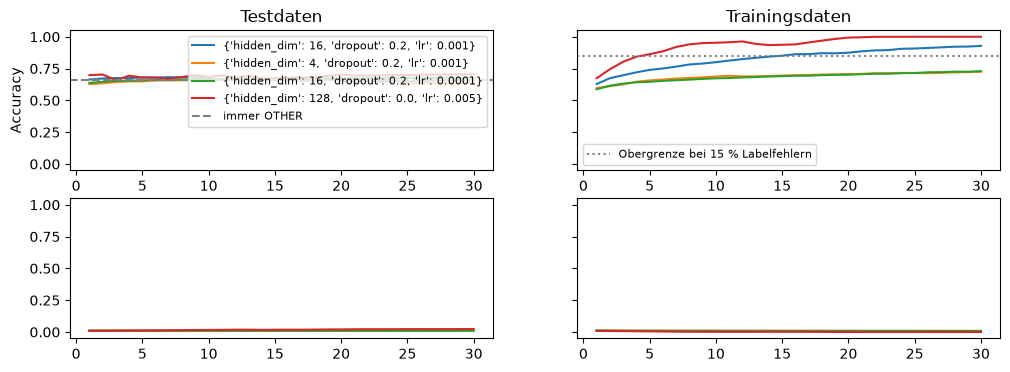

In [26]:
import matplotlib.pyplot as plt

# Hier ändern: jede Zeile ist eine Kombination, die 30 Epochen trainiert wird
varianten = [
    {"hidden_dim": 16, "dropout": 0.2, "lr": 1e-3},  # Ausgangsmodell von oben
    {"hidden_dim": 4, "dropout": 0.2, "lr": 1e-3},  # kleinerer Hidden State
    {"hidden_dim": 16, "dropout": 0.2, "lr": 1e-4},  # zehnmal kleinere Lernrate
    {"hidden_dim": 128, "dropout": 0.0, "lr": 5e-3},  # großes Netz, kein Dropout, hohe Lernrate
]

# Zwei Diagramme nebeneinander mit gemeinsamer y-Achse
fig, ((links, rechts), (unten_links, unten_rechts)) = plt.subplots(2, 2, figsize=(12, 4), sharey=True)
for variante in varianten:
    torch.manual_seed(0)  # gleiche Startgewichte und Batch-Reihenfolge für einen fairen Vergleich
    model = RNN(hidden_dim=variante["hidden_dim"], dropout=variante["dropout"])
    optimizer=torch.optim.AdamW(model.parameters(), lr=variante["lr"])
    loss_fn = nn.CrossEntropyLoss()
    train_loss, test_loss, train_kurve, test_kurve = train_model(model, optimizer, loss_fn, train_dataloader, test_dataloader, device=device, epochs=30)
    epochen = range(1, len(test_kurve) + 1)
    links.plot(epochen, test_kurve, label=str(variante))
    rechts.plot(epochen, train_kurve)  # gleiche Farbreihenfolge wie links, daher keine zweite Legende
    unten_links.plot(epochen, test_loss, label=str(variante))
    unten_rechts.plot(epochen, train_loss)  # gleiche Farbreihenfolge


# Waagerechte Bezugslinien
links.axhline(anteil_other, color="gray", linestyle="--", label="immer OTHER")
rechts.axhline(0.85, color="gray", linestyle=":", label="Obergrenze bei 15 % Labelfehlern")
links.set(title="Testdaten", xlabel="Epoche", ylabel="Accuracy")
rechts.set(title="Trainingsdaten", xlabel="Epoche")
links.legend(fontsize=8)
rechts.legend(fontsize=8)
plt.show()